# 12 · The supply chain: drought → sell-off → herd → price

**Milestone 4, item 4.4** · see `docs/MILESTONES.md`

## What we're looking for

Notebook 11 found that sudden events explain little of beef's rise. The slow explanation
(D17) is a chain of four links:

> **Drought** dries up pasture and hay, so **ranchers sell cows** they can't feed. Fewer
> cows means a **smaller herd** and fewer calves for years, so there's **less beef** and
> **prices rise**.

Notebook 07 showed the chain *looks* right on a chart. This notebook measures each link:

1. **Drought → sell-off:** how much does drought raise the share of beef cows sold for
   slaughter, and how quickly?
2. **Sell-off → herd:** how much does a bigger sell-off shrink the herd?
3. **Herd → price:** how much does a smaller herd raise the inflation-adjusted beef price?
4. **Putting it together:** does the chain account for beef's rise since 2019, and how
   much of that is down to drought?

**Why we work in years, not months.** The herd is counted once a year (January 1), and
monthly drought and slaughter figures move slowly, so each month mostly repeats the one
before. Twelve months of a slow-moving series aren't twelve independent observations. One
row per year is more honest, even though it leaves few rows: 16 years for the first two
links (2010–2025) and 12 for the third (2015–2026; beef prices start in 2015, D3).

**Sections**
1. Setup and the yearly table
2. Link 1: drought → sell-off
3. Link 2: sell-off → herd
4. Link 3: herd → price
5. Putting the chain together
6. The 2026 puzzle
7. What we found, and what's next

## Reading guide (no statistics background needed)

**What this notebook does:** it measures each step of the chain *drought → ranchers sell
cows → smaller herd → higher beef price*, to see how much each step matters and how
quickly.

**Words you'll see:**
- **Sell-off rate:** the share of the nation's beef cows sold for slaughter in a year.
- **Break-even rate:** how much of the herd can be sold in a year without the herd
  shrinking (about 1 in 10), because young females replace the cows sold.
- **Slope:** how much one thing changes when the other changes by one unit, for example
  how many more cows are sold when drought covers more of cattle country.
- **R² ("R-squared"):** how well the pattern fits, from 0 (not at all) to 1 (perfectly).
- **P-value:** how likely a pattern this strong would be by pure chance. Below 0.05
  means unlikely.
- **Elasticity:** the percent change in price for a 1% change in the herd. −1.8 means a
  1% smaller herd goes with a 1.8% higher price.
- **Log:** a way of measuring things in percentage terms, used so the results come out
  as percents.
- **Newey–West (HAC):** a correction that keeps the results from looking more certain
  than they are, because one year is related to the next.
- **Robustness check:** re-testing a result a different way to make sure it isn't a
  coincidence.
- **What-if:** an estimate of what would have happened under different conditions, here
  a normal drought instead of a severe one.

**If you only read one part:** section 7, *What we found*.

**Want the whole project in plain language?** See *Findings and methods explained*: `docs/FINDINGS.md` in the repo, or **Docs** in the bar at the top of the project site.

## 1 · Setup and the yearly table

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from dotenv import find_dotenv

warnings.filterwarnings("ignore")

env_path = find_dotenv()
PROJECT_ROOT = Path(env_path).parent if env_path else Path.cwd().parent
df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "master_monthly.csv", parse_dates=["date"]).set_index("date")
BASE_MONTH = df["cpi_all_items"].last_valid_index()
BEEF, DROUGHT, HERD = "#9A3B2E", "#B07D2B", "#5B3A1E"

def style(ax):
    ax.grid(alpha=0.3)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

by_year = df.groupby(df.index.year)
years = pd.DataFrame({
    "drought_pct": by_year["drought_cattle_d2_plus_pct"].mean(),     # avg % of cattle country in severe drought or worse
    "cows_slaughtered": by_year["slaughter_beef_cows_slaughtered"].sum(),
    "months_of_data": by_year["slaughter_beef_cows_slaughtered"].count(),
    "herd_jan1": by_year["herd_beef_cows_jan1"].first(),            # beef cows on January 1
    "beef_price_real": by_year["beef_price_real"].mean(),           # ground beef, $/lb in latest-month dollars
})
years.index.name = "year"
# Sell-off rate: cows slaughtered during the year as a % of the herd on January 1
years["selloff_rate"] = years["cows_slaughtered"] / years["herd_jan1"] * 100
# Herd change: from this January 1 to next January 1
years["herd_change_pct"] = (years["herd_jan1"].shift(-1) / years["herd_jan1"] - 1) * 100
full = years[years["months_of_data"] == 12]  # 2026 is a partial year; kept aside for section 6

years.assign(herd_jan1=lambda d: (d["herd_jan1"] / 1e6).round(2),
             cows_slaughtered=lambda d: (d["cows_slaughtered"] / 1e6).round(2)) \
     .drop(columns="months_of_data").round(2) \
     .rename(columns={"herd_jan1": "herd_jan1 (millions)", "cows_slaughtered": "cows_slaughtered (millions)"})

,drought_pct,cows_slaughtered (millions),herd_jan1 (millions),beef_price_real,selloff_rate,herd_change_pct
year,,,,,,
2010,2.74,3.63,31.44,NaN,11.55,-1.68
2011,28.26,3.80,30.91,NaN,12.28,-2.04
2012,38.53,3.34,30.28,NaN,11.04,-2.15
2013,33.16,3.13,29.63,NaN,10.56,-2.28
2014,15.03,2.56,28.96,NaN,8.86,1.30
2015,6.00,2.24,29.33,5.92,7.62,2.84
2016,3.05,2.54,30.16,5.27,8.43,3.34
2017,6.58,2.78,31.17,5.01,8.93,0.95
2018,11.63,3.02,31.47,4.99,9.61,0.55


### How to read it
One row per year:
- **drought_pct:** the average share of cattle country in severe drought or worse
  that year, weighted by where the beef cows are (D26).
- **selloff_rate:** the share of the January 1 herd that was slaughtered during the
  year.
- **herd_change_pct:** how much the herd grew or shrank by the next January 1.
- **beef_price_real:** the average inflation-adjusted price of ground beef.

2026 has only nine months of slaughter so far, so it's left out of links 1 and 2 and
looked at separately in section 6. Link 3 does use it: its herd (January 1) is final,
and its price is the average of the nine months so far.

### What it means
The table shows **two full cattle cycles**:
- **2010–2014: down.** The 2011–2013 drought came with sell-off rates of 11–12%, and the herd shrank every year.
- **2014–2019: up.** Drought was mild, sell-off rates fell to 7.6–9.6%, and the herd grew back to 31.6 million.
- **2019–2026: down again.** The sell-off peaked at 13.2% in 2022, and the herd fell to 27.6 million, its smallest in this data.

The real beef price mirrors the herd: it fell from 2015 to 2018 while the herd grew, and has risen every year since 2019 as the herd shrank.

## 2 · Link 1: drought → sell-off

**What we're looking for:** whether years with more drought are years when ranchers sell
off more of their cows, how big the effect is, and whether it comes the same year or the
year after.

**The method:** a straight-line fit (ordinary least squares, OLS) of the sell-off rate on
drought. The **slope** says how many extra percentage points of the herd are sold for each
extra point of drought. **R²** says how much of the year-to-year variation drought
accounts for (0 = none, 1 = all). The **p-value** says how likely a slope that big would
be if drought had no effect. Because one year's sell-off is related to the next, the
p-values use a correction for that (Newey–West, also called HAC).

In [2]:
def fit(data, y, xs):
    """OLS of y on xs with Newey-West (HAC) standard errors; drops rows with gaps."""
    d = data[[y] + xs].dropna()
    return sm.OLS(d[y], sm.add_constant(d[xs])).fit(cov_type="HAC", cov_kwds={"maxlags": 2})


link1 = full.assign(drought_prev_year=years["drought_pct"].shift(1))
same_year = fit(link1, "selloff_rate", ["drought_pct"])
prev_year = fit(link1, "selloff_rate", ["drought_prev_year"])
pd.DataFrame({
    "slope": [same_year.params.iloc[1], prev_year.params.iloc[1]],
    "p_value": [same_year.pvalues.iloc[1], prev_year.pvalues.iloc[1]],
    "R2": [same_year.rsquared, prev_year.rsquared],
    "years": [int(same_year.nobs), int(prev_year.nobs)],
}, index=["drought the same year", "drought the year before"]).round(3)

,slope,p_value,R2,years
drought the same year,0.081,0.005,0.382,16
drought the year before,0.024,0.369,0.035,15


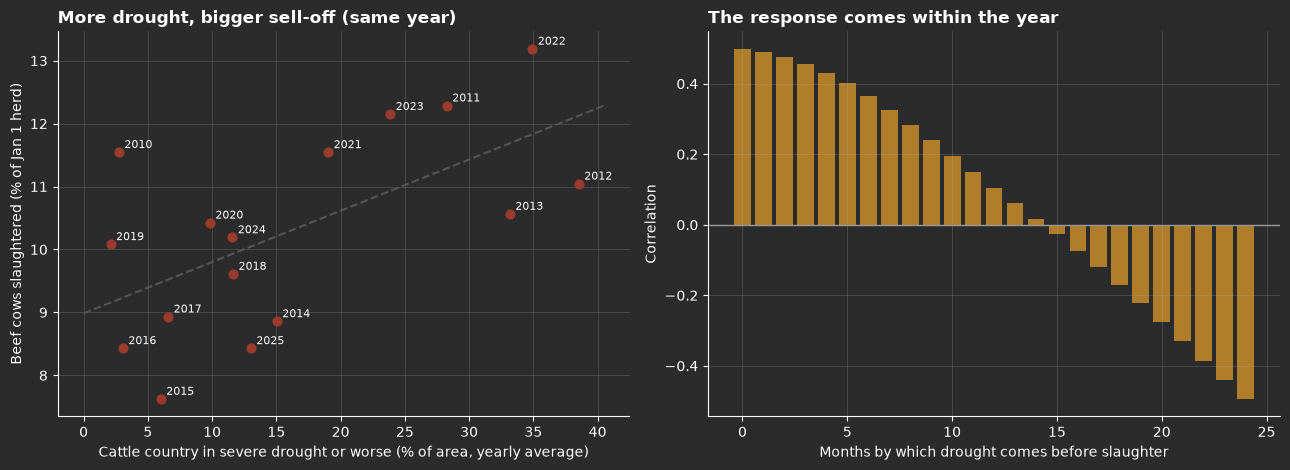

Strongest correlation at a delay of 0 months; 10 more points of drought -> +0.81 points of the herd sold (about 245 thousand cows)


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
ax.scatter(full["drought_pct"], full["selloff_rate"], color=BEEF, s=40, zorder=3)
for yr, r in full.iterrows():
    ax.annotate(str(yr), (r["drought_pct"], r["selloff_rate"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
xs = np.linspace(0, full["drought_pct"].max() * 1.05, 50)
ax.plot(xs, same_year.params.iloc[0] + same_year.params.iloc[1] * xs, color="#555555", linestyle="--")
ax.set_xlabel("Cattle country in severe drought or worse (% of area, yearly average)")
ax.set_ylabel("Beef cows slaughtered (% of Jan 1 herd)")
ax.set_title("More drought, bigger sell-off (same year)", loc="left", fontweight="bold")
style(ax)

# How quickly: monthly correlation between the past-12-month drought and past-12-month slaughter, at different delays
drought_12 = df["drought_cattle_d2_plus_pct"].rolling(12).mean()
slaughter_12 = df["slaughter_beef_cows_slaughtered_12mo"]
delays = range(0, 25)
corr = [slaughter_12.corr(drought_12.shift(k)) for k in delays]
ax = axes[1]
ax.bar(list(delays), corr, color=DROUGHT)
ax.axhline(0, color="#999999", linewidth=1)
ax.set_xlabel("Months by which drought comes before slaughter")
ax.set_ylabel("Correlation")
ax.set_title("The response comes within the year", loc="left", fontweight="bold")
style(ax)
fig.tight_layout()
plt.show()
print(f"Strongest correlation at a delay of {int(np.argmax(corr))} months; "
      f"10 more points of drought -> {same_year.params.iloc[1] * 10:+.2f} points of the herd sold "
      f"(about {same_year.params.iloc[1] * 10 / 100 * full['herd_jan1'].mean() / 1e3:,.0f} thousand cows)")

### How to read it
**Table:** one row per version of the fit. The first uses drought in the same year as the
sell-off; the second uses drought the year before.

**Left chart:** each dot is a year. Further right means more drought; higher means a
bigger share of the herd was slaughtered. The dashed line is the fitted straight line.

**Right chart:** the correlation (−1 to 1) between drought and cow slaughter when drought
is shifted earlier by 0 to 24 months. The tallest bar shows the delay at which the two
line up best.

### What it means
**Drought clearly raises the sell-off, in the same year.** Each extra 10 points of cattle country in severe drought goes with about **0.8 points more of the herd sold**, roughly **245,000 extra cows**. That's unlikely to be chance (p = 0.005).

Drought the year before shows no relationship (p = 0.37), and the right chart says the same thing: drought and slaughter line up best with **no delay**, and the link fades within about a year. Ranchers sell when the pasture dries up, not a year later. (The negative bars at long delays reflect the cycle: a big sell-off is usually followed by years of keeping cows to rebuild.)

**Drought isn't the only reason ranchers sell.** It accounts for about 4 in 10 of the year-to-year swings (R² = 0.38). The years far from the line show why:
- **2010 and 2019–2020:** high sell-offs with little drought. Ranchers had other reasons to sell.
- **2012–2013:** lower sell-offs than the drought predicts. Many cows had already gone in 2011.

## 3 · Link 2: sell-off → herd

**What we're looking for:** how much the herd shrinks when the sell-off is bigger, and the
**break-even rate**, the share of cows that can be sold in a year without the herd
shrinking. Ranchers always sell some cows (old or unproductive ones) and replace them with
young females (heifers); the herd shrinks only when sales outrun replacements.

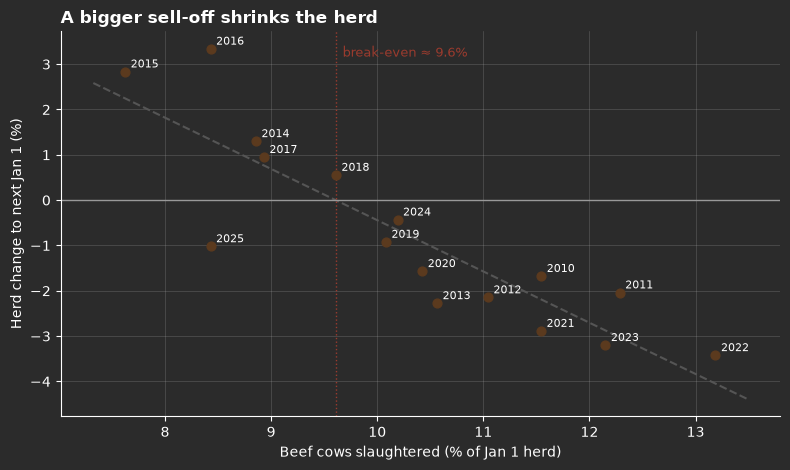

Slope -1.13 (each extra point of the herd sold -> herd -1.13%), R2 0.76, p 0.0000, 16 years; break-even 9.6%


In [4]:
link2 = fit(full, "herd_change_pct", ["selloff_rate"])
break_even = -link2.params.iloc[0] / link2.params.iloc[1]

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(full["selloff_rate"], full["herd_change_pct"], color=HERD, s=40, zorder=3)
for yr, r in full.dropna(subset=["herd_change_pct"]).iterrows():
    ax.annotate(str(yr), (r["selloff_rate"], r["herd_change_pct"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
xs = np.linspace(full["selloff_rate"].min() - 0.3, full["selloff_rate"].max() + 0.3, 50)
ax.plot(xs, link2.params.iloc[0] + link2.params.iloc[1] * xs, color="#555555", linestyle="--")
ax.axhline(0, color="#999999", linewidth=1)
ax.axvline(break_even, color=BEEF, linewidth=1, linestyle=":")
ax.annotate(f"break-even ≈ {break_even:.1f}%", (break_even, ax.get_ylim()[1] * 0.85), xytext=(5, 0),
            textcoords="offset points", color=BEEF, fontsize=9)
ax.set_xlabel("Beef cows slaughtered (% of Jan 1 herd)")
ax.set_ylabel("Herd change to next Jan 1 (%)")
ax.set_title("A bigger sell-off shrinks the herd", loc="left", fontweight="bold")
style(ax)
fig.tight_layout()
plt.show()
print(f"Slope {link2.params.iloc[1]:.2f} (each extra point of the herd sold -> herd {link2.params.iloc[1]:.2f}%), "
      f"R2 {link2.rsquared:.2f}, p {link2.pvalues.iloc[1]:.4f}, {int(link2.nobs)} years; break-even {break_even:.1f}%")

### How to read it
Each dot is a year: how much of the herd was sold (across) and how much the herd changed
by the next January 1 (up = grew, down = shrank). The dotted line marks the break-even
sell-off rate, where the fitted line crosses zero.

### What it means
This is the tightest link (R² = 0.76): **each extra point of the herd sold shrinks the herd by about 1.1%** by the next January. The **break-even is about 9.6%**: sell more than that in a year and the herd shrinks, sell less and it grows. From 2019 to 2023, every year was above break-even, and 2022's 13.2% was the furthest above it.

The one clear exception is **2025**. Ranchers sold only 8.4% of their cows, below break-even, yet the herd still shrank 1%. The likely reason is replacements: heifers (young females) made up about 39% of the young cattle slaughtered that year (heifers plus steers), against about 32% in 2016, when the herd was growing. Heifers sent to slaughter can't join the herd.

## 4 · Link 3: herd → price

**What we're looking for:** how much the inflation-adjusted price of ground beef rises when
the herd is smaller. We fit the **log** of the price on the **log** of the herd, so the
slope is an **elasticity**: the percent change in price for a 1% change in the herd. An
elasticity of −1.5 would mean a 1% smaller herd goes with a 1.5% higher real price.

We also check the timing (the herd this January, last January, or the one before) and
two robustness checks, because with only 12 years and both series trending, a strong fit
could be a coincidence of two trends:
- **Year-to-year changes:** does a year when the herd shrank more also see a bigger
  price rise?
- **With a time trend:** does the herd still matter once a steady upward drift in prices
  is allowed for?

In [5]:
prices = years.dropna(subset=["beef_price_real"]).copy()
prices["log_price"] = np.log(prices["beef_price_real"])
for lag in [0, 1, 2]:
    prices[f"log_herd_lag{lag}"] = np.log(years["herd_jan1"].shift(lag))
prices["trend"] = prices.index - prices.index.min()

rows = {}
for lag, label in [(0, "herd this Jan 1"), (1, "herd last Jan 1"), (2, "herd 2 years before")]:
    r = fit(prices, "log_price", [f"log_herd_lag{lag}"])
    rows[label] = [r.params.iloc[1], r.pvalues.iloc[1], r.rsquared, int(r.nobs)]
changes = prices[["log_price", "log_herd_lag0"]].diff().dropna()
r = fit(changes, "log_price", ["log_herd_lag0"])
rows["year-to-year changes"] = [r.params.iloc[1], r.pvalues.iloc[1], r.rsquared, int(r.nobs)]
r = fit(prices, "log_price", ["log_herd_lag0", "trend"])
rows["with a time trend"] = [r.params["log_herd_lag0"], r.pvalues["log_herd_lag0"], r.rsquared, int(r.nobs)]
link3_table = pd.DataFrame(rows, index=["elasticity", "p_value", "R2", "years"]).T
link3 = fit(prices, "log_price", ["log_herd_lag0"])
ELASTICITY = link3.params.iloc[1]
link3_table.round(3)

,elasticity,p_value,R2,years
herd this Jan 1,-1.800,0.000,0.808,12.0
herd last Jan 1,-1.835,0.000,0.678,12.0
herd 2 years before,-1.448,0.060,0.323,12.0
year-to-year changes,-1.587,0.024,0.356,11.0
with a time trend,-1.672,0.000,0.812,12.0


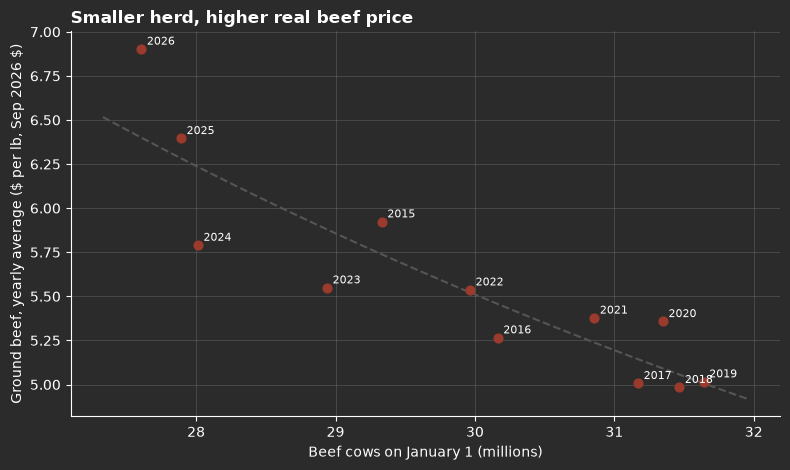

Elasticity -1.80: a 1% smaller herd goes with a 1.8% higher real beef price


In [6]:
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(prices["herd_jan1"] / 1e6, prices["beef_price_real"], color=BEEF, s=40, zorder=3)
for yr, r in prices.iterrows():
    ax.annotate(str(yr), (r["herd_jan1"] / 1e6, r["beef_price_real"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
hs = np.linspace(prices["herd_jan1"].min() * 0.99, prices["herd_jan1"].max() * 1.01, 50)
ax.plot(hs / 1e6, np.exp(link3.params.iloc[0] + ELASTICITY * np.log(hs)), color="#555555", linestyle="--")
ax.set_xlabel("Beef cows on January 1 (millions)")
ax.set_ylabel(f"Ground beef, yearly average ($ per lb, {BASE_MONTH:%b %Y} $)".replace("$", r"\$"))
ax.set_title("Smaller herd, higher real beef price", loc="left", fontweight="bold")
style(ax)
fig.tight_layout()
plt.show()
print(f"Elasticity {ELASTICITY:.2f}: a 1% smaller herd goes with a {-ELASTICITY:.1f}% higher real beef price")

### How to read it
**Table:** one row per version of the fit. **elasticity** is the % change in the real
beef price for a 1% bigger herd (negative = smaller herd, higher price). The last two
rows are the robustness checks.

**Chart:** each dot is a year (2015 on). Further left is a smaller herd; higher is a
higher real price. The dashed curve is the fitted elasticity.

### What it means
**A 1% smaller herd goes with about a 1.8% higher real beef price** (p < 0.001, R² = 0.81).

The robustness checks say this isn't just two trends that happen to line up:
- **With a time trend** allowed for, the elasticity barely changes (−1.67).
- **In year-to-year changes**, years when the herd shrank more also saw bigger price rises (−1.59, p = 0.02).

**Timing:** this January's herd fits best, last January's almost as well, and the herd two years earlier much less. So the price responds within about a year of the herd changing.

**Why more than 1:** people don't cut back much on beef when it gets dearer. So when there's less beef, the price has to rise by *more* than the supply fell before buyers give up enough of it.

## 5 · Putting the chain together

**What we're looking for:** two things.
1. **Does the chain account for beef's rise?** Using only the herd and the elasticity
   from section 4, what real price change would we expect from 2019 to 2025, and how
   does that compare with what happened?
2. **How much of it is drought?** A *what-if*: suppose the 2020–2023 drought had been no
   worse than the 2015–2019 average. Using the fitted links, how much smaller would the
   sell-off have been, how much bigger the herd, and how much lower the price?

In [7]:
start, end = 2019, 2025
herd_ratio = years.loc[end, "herd_jan1"] / years.loc[start, "herd_jan1"]
expected = (herd_ratio ** ELASTICITY - 1) * 100
actual = (years.loc[end, "beef_price_real"] / years.loc[start, "beef_price_real"] - 1) * 100
print(f"Herd, Jan 1 {start} to Jan 1 {end}: {(herd_ratio - 1) * 100:+.1f}%")
print(f"Real beef price, {start} to {end}: expected from the herd {expected:+.1f}%, actual {actual:+.1f}%")

# What-if: drought 2020-2023 at the 2015-2019 average; every other influence unchanged
normal = full.loc[2015:2019, "drought_pct"].mean()
slope1, slope2 = same_year.params.iloc[1], link2.params.iloc[1]
whatif = years["herd_jan1"].copy()
for yr in range(2020, end + 1):
    extra_selloff = (full.loc[yr, "drought_pct"] - normal) * slope1 if yr <= 2023 else 0.0
    change = years.loc[yr, "herd_change_pct"] - slope2 * extra_selloff
    whatif.loc[yr + 1] = whatif.loc[yr] * (1 + change / 100)

path = pd.DataFrame({"actual herd": years["herd_jan1"], "herd without the extra drought": whatif}).loc[start:end + 1] / 1e6
drought_share = (path.iloc[-1, 1] - path.iloc[-1, 0]) / (path.iloc[0, 0] - path.iloc[-1, 0]) * 100
price_from_drought = ((years.loc[end, "herd_jan1"] / whatif.loc[end]) ** ELASTICITY - 1) * 100
print(f"\nNormal (2015-2019) drought: {normal:.1f}% of cattle country")
print(f"Herd loss {start}-{end + 1} explained by the extra drought: about {drought_share:.0f}%")
print(f"Real beef price in {end} attributable to the extra drought: about {price_from_drought:+.0f}% of the {actual:+.0f}%")
path.round(2)

Herd, Jan 1 2019 to Jan 1 2025: -11.8%
Real beef price, 2019 to 2025: expected from the herd +25.5%, actual +27.5%

Normal (2015-2019) drought: 5.9% of cattle country
Herd loss 2019-2026 explained by the extra drought: about 43%
Real beef price in 2025 attributable to the extra drought: about +11% of the +28%


,actual herd,herd without the extra drought
year,,
2019,31.64,31.64
2020,31.35,31.35
2021,30.86,30.97
2022,29.97,30.45
2023,28.94,30.22
2024,28.01,29.76
2025,27.89,29.63
2026,27.61,29.33


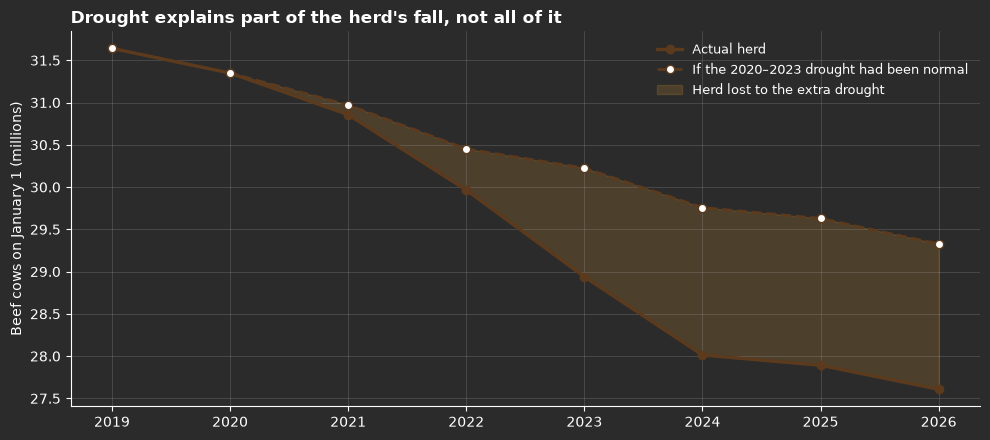

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(path.index, path["actual herd"], color=HERD, linewidth=2.4, marker="o", label="Actual herd")
ax.plot(path.index, path["herd without the extra drought"], color=HERD, linewidth=2, linestyle="--", marker="o",
        markerfacecolor="white", label="If the 2020–2023 drought had been normal")
ax.fill_between(path.index, path["actual herd"], path["herd without the extra drought"], color=DROUGHT, alpha=0.25,
                label="Herd lost to the extra drought")
ax.set_ylabel("Beef cows on January 1 (millions)")
ax.set_title("Drought explains part of the herd's fall, not all of it", loc="left", fontweight="bold")
ax.legend(frameon=False, fontsize=9)
style(ax)
fig.tight_layout()
plt.show()

### How to read it
**First printout:** the herd's change from 2019 to 2025, the real price change the
elasticity predicts from that alone, and the actual change.

**Second printout and chart:** the solid line is the actual herd. The dashed line is the
what-if herd, with the 2020–2023 drought replaced by a normal level and everything else
left as it was. The shaded gap is the part of the herd loss the fitted links put down to
drought.

### What it means
**The herd alone accounts for almost all of beef's real price rise.** From January 2019 to January 2025 the herd shrank 11.8%. With the elasticity of −1.8, that predicts a **+25.5%** real price rise; the actual rise was **+27.5%**.

**Drought is a big part of the story, but not all of it.** If the 2020–2023 drought had been as mild as 2015–2019 (about 6% of cattle country), the fitted links say:
- The herd would have lost about **43% less**: 29.3 million cows in 2026 instead of 27.6 million.
- The 2025 real beef price would have been about **11 points lower** (out of the 28% rise).

The rest came from ranchers' other choices. The herd was already shrinking in 2019 and 2020, with little drought, and in 2024–2025 many heifers still went to slaughter instead of joining the herd.

## 6 · The 2026 puzzle

**What we're looking for:** 2026 was left out of the fits because it's a partial year. But
it's worth a look, because drought came back hard. Does the chain predict what's
happening?

In [9]:
months_2026 = int(years.loc[2026, "months_of_data"])
rate_2026_annual = years.loc[2026, "selloff_rate"] * 12 / months_2026
predicted_2026 = same_year.params.iloc[0] + same_year.params.iloc[1] * years.loc[2026, "drought_pct"]
print(f"2026 so far ({months_2026} months): drought {years.loc[2026, 'drought_pct']:.0f}% of cattle country "
      f"(2022: {years.loc[2022, 'drought_pct']:.0f}%)")
print(f"Sell-off rate, scaled to a full year: {rate_2026_annual:.1f}% "
      f"(link 1 predicts {predicted_2026:.1f}%; break-even {break_even:.1f}%)")
same_months = df[df.index.month <= months_2026]
print("\nBeef cows slaughtered in the same months of each year (millions):")
print((same_months["slaughter_beef_cows_slaughtered"].groupby(same_months.index.year).sum() / 1e6).loc[2019:].round(2).to_string())

2026 so far (9 months): drought 33% of cattle country (2022: 35%)
Sell-off rate, scaled to a full year: 7.3% (link 1 predicts 11.7%; break-even 9.6%)

Beef cows slaughtered in the same months of each year (millions):
date
2019    2.30
2020    2.38
2021    2.59
2022    2.94
2023    2.55
2024    2.14
2025    1.75
2026    1.50


### How to read it
The first lines compare 2026's drought with 2022's, and 2026's sell-off rate (scaled up
from the months so far) with what link 1 would predict for that much drought. The list
compares cow slaughter over the same months of each year, so the partial year is a fair
comparison.

### What it means
**2026 breaks the pattern.** Drought covers 33% of cattle country, almost as much as 2022's 35%, yet cow slaughter for January–September is the **lowest of any year since at least 2019**: 1.50 million, against 2.94 million in 2022. Scaled to a full year, the sell-off rate is about **7.3%**. Link 1 predicts 11.7% for that much drought, and break-even is 9.6%.

Ranchers are **holding on to their cows despite the drought**. This notebook can't say why, but two likely reasons are record cattle prices, which make every cow worth keeping, and a herd so small there's little left to cull.

If it lasts, the herd could start growing again in 2027. In the short run that keeps beef *scarce*, because cows and heifers kept for breeding aren't being turned into beef. That fits the 2026 price sitting above the fitted line in section 4.

## 7 · What we found

1. **Every link in the chain shows up in the data, and each acts within about a year.**
   - Drought → sell-off: same year; 10 more points of drought means about 0.8 points more of the herd sold.
   - Sell-off → herd: selling more than about 9.6% of the herd in a year shrinks it, by about 1.1% per extra point.
   - Herd → price: a 1% smaller herd goes with about a 1.8% higher real beef price, and that holds up under two robustness checks.
2. **The shrinking herd accounts for almost all of beef's real price rise since 2019** (+25% expected from the herd alone, +28% actual). Together with notebook 11, that means beef's rise is a supply story, not a series of shocks.
3. **Drought is the biggest single push identified, but not the whole story.** It accounts for roughly 40% of the herd loss and about 11 points of the 28% real price rise. Ranchers' other choices, such as selling in 2019–2020 and sending heifers to slaughter in 2024–2025, account for the rest.
4. **2026 breaks the pattern.** Drought is back, but ranchers are keeping their cows. That could be the start of rebuilding, which keeps beef scarce in the short run before it brings prices down.

### Limits worth knowing
- **Few years.** 16 years for links 1 and 2, 12 for link 3. The results are clear
  enough to be useful, but the exact sizes could move a fair amount with more years.
  A longer price and herd history (BLS and NASS go back decades) would help most with
  link 3.
- **Other things move too.** Demand for beef, imports, feed and fuel costs, and packer
  margins all change over the same years. The fits don't separate them out; a fit can
  show the herd and price move together, not that nothing else mattered.
- **Ranchers decide; drought only pushes.** The sell-off also depends on cattle prices,
  interest rates and what ranchers expect. 2026 shows the push from drought can be
  outweighed.
- **The what-if assumes the links stay fixed.** It changes only drought and keeps every
  other influence as it was.

## What's next and why

**Item 4.5: the verdict.** Notebooks 07–12 have now answered the project's questions one
at a time: how much prices rose, which events mattered, and what drives beef. Item 4.5
pulls them into one plain-language answer to *"Are today's prices justified?"*, and adds
the two short pieces still to do, 4.1 (meat vs. inflation) and 4.2 (who gets each beef
dollar), as part of it, since most of that work is already in notebook 07.